Завдання 1

Імпорт бібліотек та завантаження датасета

Версія TensorFlow: 2.21.0
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2329s 14us/step
Розмір навчальної вибірки: (50000, 32, 32, 3)
Розмір тестової вибірки: (10000, 32, 32, 3)


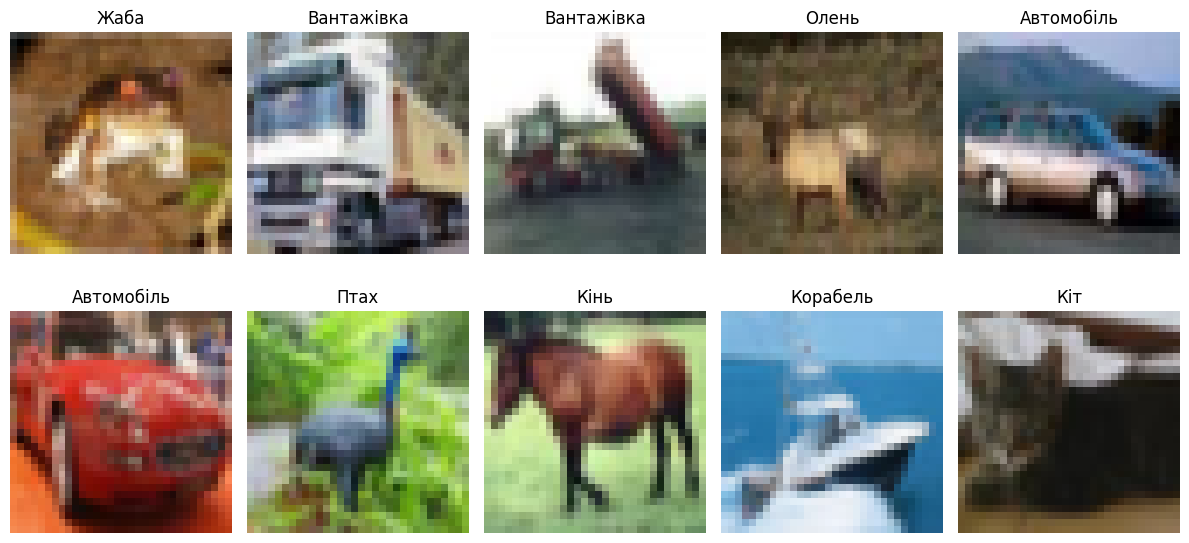

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("Версія TensorFlow:", tf.__version__)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

class_names = [
    'Літак', 'Автомобіль', 'Птах', 'Кіт', 'Олень',
    'Собака', 'Жаба', 'Кінь', 'Корабель', 'Вантажівка'
]

print("Розмір навчальної вибірки:", x_train.shape)
print("Розмір тестової вибірки:", x_test.shape)

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')

plt.tight_layout()
plt.show()

Підготовка даних

In [2]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

x_train_small = x_train[:10000]
y_train_small = y_train[:10000]

x_test_small = x_test[:2000]
y_test_small = y_test[:2000]

print("Навчальна вибірка:", x_train_small.shape)
print("Тестова вибірка:", x_test_small.shape)


Навчальна вибірка: (10000, 32, 32, 3)
Тестова вибірка: (2000, 32, 32, 3)


Створення архітектури нейронної мережі

In [3]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Навчання моделі з колбеками

In [4]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    min_lr=0.00001
)

history = model.fit(
    x_train_small,
    y_train_small,
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 140ms/step - accuracy: 0.2200 - loss: 2.0975 - val_accuracy: 0.3470 - val_loss: 1.8581 - learning_rate: 0.0010
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.3528 - loss: 1.7743 - val_accuracy: 0.3945 - val_loss: 1.6437 - learning_rate: 0.0010
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 125ms/step - accuracy: 0.4054 - loss: 1.6148 - val_accuracy: 0.4450 - val_loss: 1.5094 - learning_rate: 0.0010
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.4379 - loss: 1.5253 - val_accuracy: 0.4970 - val_loss: 1.4110 - learning_rate: 0.0010
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.4841 - loss: 1.4175 - val_accuracy: 0.4990 - val_loss: 1.3562 - learning_rate: 0.0010
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 132ms/step - accuracy: 0.5051 - loss: 1.3532 - val_accuracy: 0.5355 - val_loss: 1.2613 - learning_rate: 0.0010
Epoch 7/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.5340 - l

Оцінювання моделі

In [5]:
test_loss, test_accuracy = model.evaluate(
    x_test_small,
    y_test_small,
    verbose=1
)

print("Функція втрат:", test_loss)
print("Точність моделі:", test_accuracy)


63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.5860 - loss: 1.1702
Функція втрат: 1.1702100038528442
Точність моделі: 0.5860000252723694


Побудова графіків функції втрат і точності

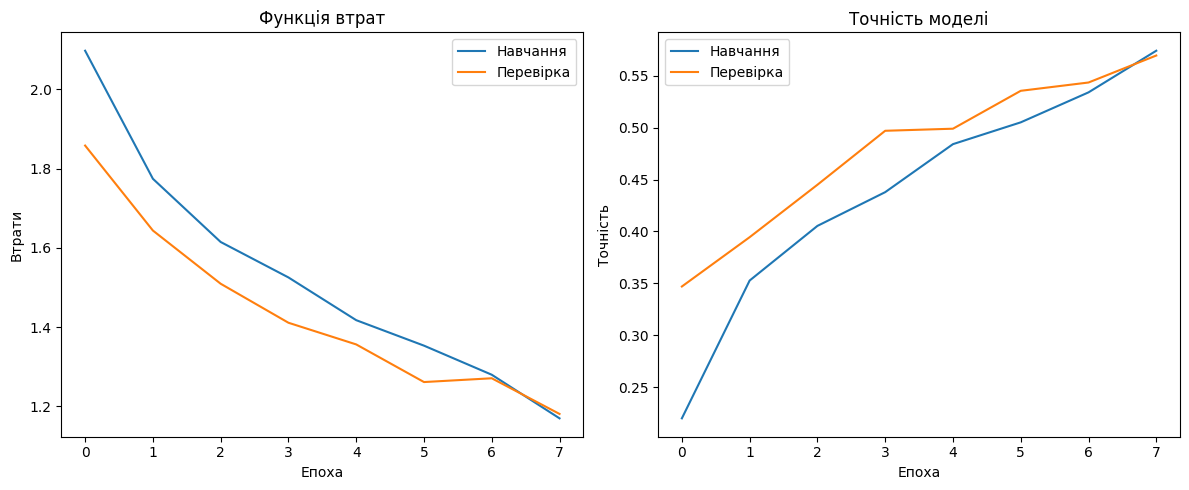

In [6]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Навчання')
plt.plot(history.history['val_loss'], label='Перевірка')
plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Навчання')
plt.plot(history.history['val_accuracy'], label='Перевірка')
plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.legend()

plt.tight_layout()
plt.show()


Класифікаційний звіт

In [7]:
y_pred = np.argmax(model.predict(x_test_small), axis=1)

print(classification_report(
    y_test_small,
    y_pred,
    target_names=class_names,
    zero_division=0
))


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step
              precision    recall  f1-score   support

       Літак       0.62      0.55      0.58       196
  Автомобіль       0.61      0.86      0.72       198
        Птах       0.43      0.39      0.41       195
         Кіт       0.45      0.34      0.39       199
       Олень       0.46      0.40      0.43       198
      Собака       0.50      0.39      0.44       185
        Жаба       0.62      0.80      0.70       216
        Кінь       0.67      0.69      0.68       193
    Корабель       0.71      0.78      0.75       217
  Вантажівка       0.65      0.60      0.62       203

    accuracy                           0.59      2000
   macro avg       0.57      0.58      0.57      2000
weighted avg       0.58      0.59      0.57      2000



Візуалізація розпізнавання

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


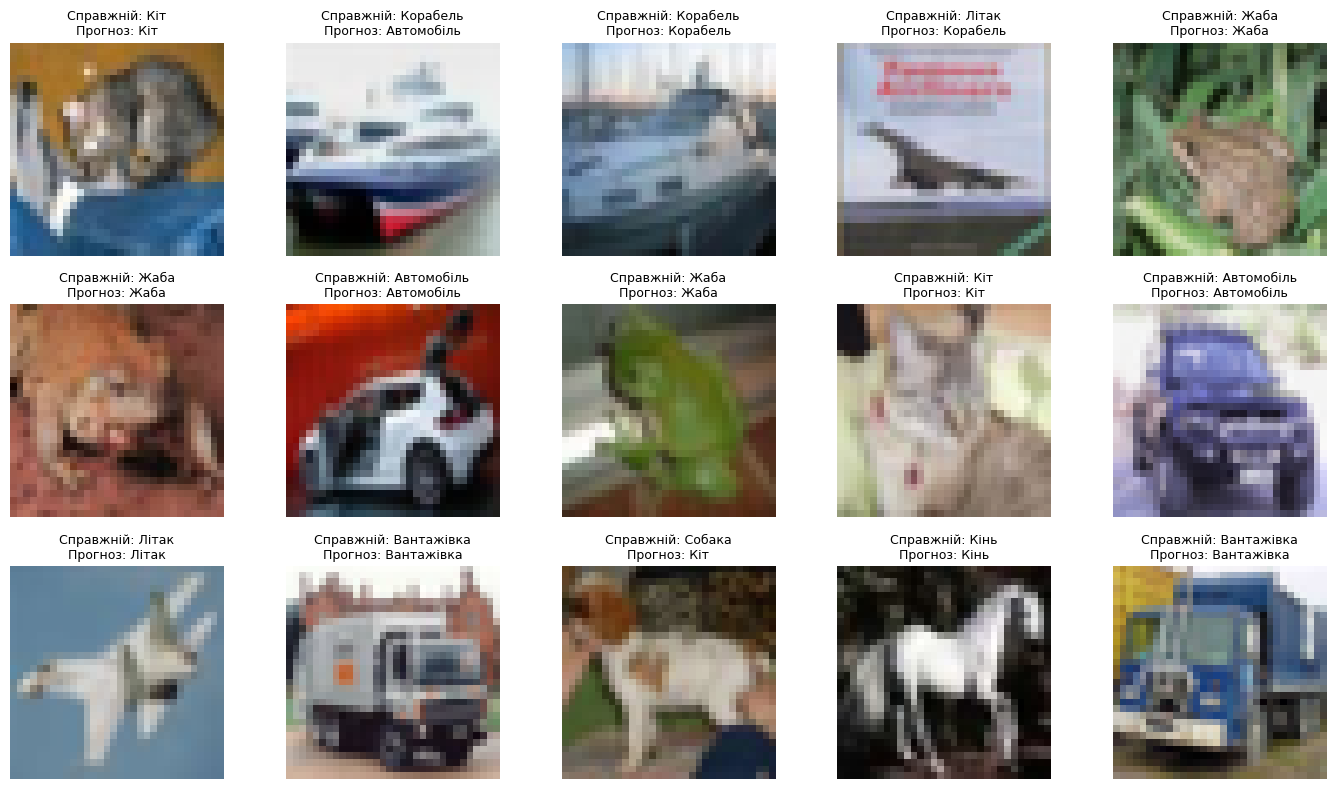

In [8]:
plt.figure(figsize=(14, 8))

predictions = model.predict(x_test_small[:15])
predicted_classes = np.argmax(predictions, axis=1)

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test_small[i])

    true_label = class_names[y_test_small[i]]
    predicted_label = class_names[predicted_classes[i]]

    plt.title(
        f'Справжній: {true_label}\nПрогноз: {predicted_label}',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


Завдання 2

Імпорт бібліотек та підготовка даних

In [9]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

x_train_vgg = x_train[:3000] * 255.0
x_test_vgg = x_test[:600] * 255.0

y_train_vgg = y_train[:3000]
y_test_vgg = y_test[:600]

print("Навчальна вибірка:", x_train_vgg.shape)
print("Тестова вибірка:", x_test_vgg.shape)


Навчальна вибірка: (3000, 32, 32, 3)
Тестова вибірка: (600, 32, 32, 3)


Створення моделі VGG16

In [10]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

vgg_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Resizing(96, 96),
    layers.Lambda(preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

vgg_model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Навчання моделі

In [11]:
early_stop_vgg = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

reduce_lr_vgg = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    min_lr=0.000001
)

history_vgg = vgg_model.fit(
    x_train_vgg,
    y_train_vgg,
    epochs=4,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop_vgg, reduce_lr_vgg],
    verbose=1
)


Epoch 1/4
75/75 ━━━━━━━━━━━━━━━━━━━━ 269s 4s/step - accuracy: 0.1283 - loss: 10.4055 - val_accuracy: 0.2650 - val_loss: 4.1607 - learning_rate: 1.0000e-04
Epoch 2/4
75/75 ━━━━━━━━━━━━━━━━━━━━ 293s 4s/step - accuracy: 0.2200 - loss: 6.8451 - val_accuracy: 0.3817 - val_loss: 2.9174 - learning_rate: 1.0000e-04
Epoch 3/4
75/75 ━━━━━━━━━━━━━━━━━━━━ 320s 4s/step - accuracy: 0.2717 - loss: 5.0687 - val_accuracy: 0.4700 - val_loss: 2.2816 - learning_rate: 1.0000e-04
Epoch 4/4
75/75 ━━━━━━━━━━━━━━━━━━━━ 291s 4s/step - accuracy: 0.3546 - loss: 3.8825 - val_accuracy: 0.5283 - val_loss: 1.8747 - learning_rate: 1.0000e-04


Тонке налаштування моделі

In [14]:
base_model.trainable = True

for layer in base_model.layers:
    if not layer.name.startswith('block5'):
        layer.trainable = False

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

vgg_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 7,146,378 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

Повторне навчання після тонкого налаштування

In [15]:
history_fine = vgg_model.fit(
    x_train_vgg,
    y_train_vgg,
    epochs=2,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop_vgg, reduce_lr_vgg],
    verbose=1
)


Epoch 1/2
75/75 ━━━━━━━━━━━━━━━━━━━━ 358s 5s/step - accuracy: 0.3875 - loss: 2.6319 - val_accuracy: 0.5500 - val_loss: 1.3780 - learning_rate: 1.0000e-05
Epoch 2/2
75/75 ━━━━━━━━━━━━━━━━━━━━ 345s 5s/step - accuracy: 0.4521 - loss: 1.7607 - val_accuracy: 0.5950 - val_loss: 1.1910 - learning_rate: 1.0000e-05


Оцінювання моделі VGG16

In [16]:
vgg_loss, vgg_accuracy = vgg_model.evaluate(
    x_test_vgg,
    y_test_vgg,
    verbose=1
)

print("Функція втрат:", vgg_loss)
print("Точність моделі VGG16:", vgg_accuracy)


19/19 ━━━━━━━━━━━━━━━━━━━━ 53s 3s/step - accuracy: 0.5567 - loss: 1.3715
Функція втрат: 1.3714704513549805
Точність моделі VGG16: 0.5566666722297668


Побудова графіків навчання

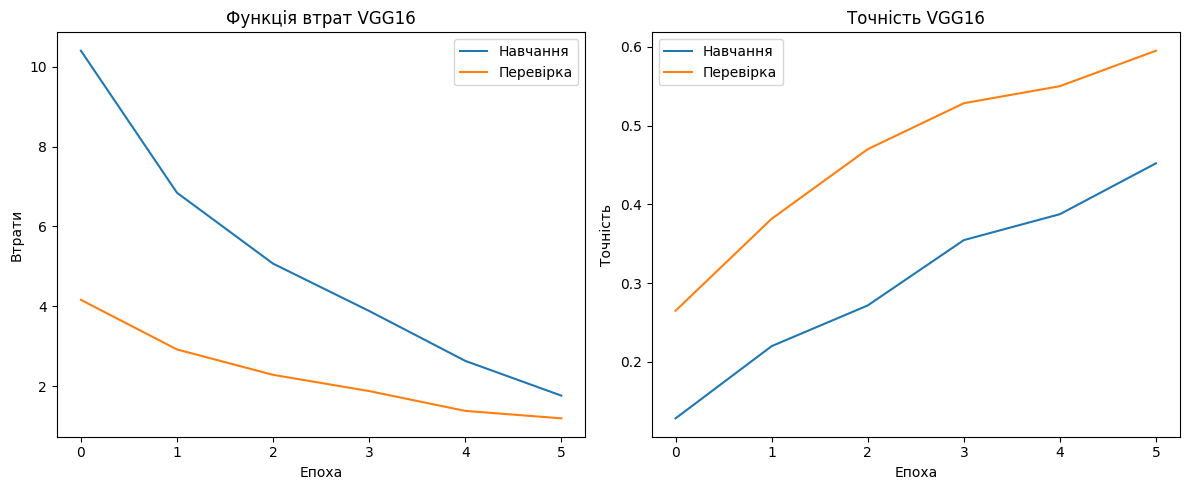

In [17]:
loss = history_vgg.history['loss'] + history_fine.history['loss']
val_loss = history_vgg.history['val_loss'] + history_fine.history['val_loss']

accuracy = history_vgg.history['accuracy'] + history_fine.history['accuracy']
val_accuracy = history_vgg.history['val_accuracy'] + history_fine.history['val_accuracy']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(loss, label='Навчання')
plt.plot(val_loss, label='Перевірка')
plt.title('Функція втрат VGG16')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(accuracy, label='Навчання')
plt.plot(val_accuracy, label='Перевірка')
plt.title('Точність VGG16')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.legend()

plt.tight_layout()
plt.show()


Класифікаційний звіт VGG16

In [18]:
y_pred_vgg = np.argmax(
    vgg_model.predict(x_test_vgg),
    axis=1
)

print(classification_report(
    y_test_vgg,
    y_pred_vgg,
    target_names=class_names,
    zero_division=0
))


19/19 ━━━━━━━━━━━━━━━━━━━━ 53s 3s/step
              precision    recall  f1-score   support

       Літак       0.57      0.45      0.50        66
  Автомобіль       0.62      0.80      0.70        46
        Птах       0.41      0.36      0.39        58
         Кіт       0.37      0.32      0.34        56
       Олень       0.35      0.49      0.41        51
      Собака       0.49      0.61      0.55        62
        Жаба       0.61      0.64      0.62        70
        Кінь       0.60      0.53      0.56        57
    Корабель       0.76      0.67      0.71        63
  Вантажівка       0.80      0.68      0.73        71

    accuracy                           0.56       600
   macro avg       0.56      0.56      0.55       600
weighted avg       0.57      0.56      0.56       600



Візуалізація розпізнавання VGG16

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


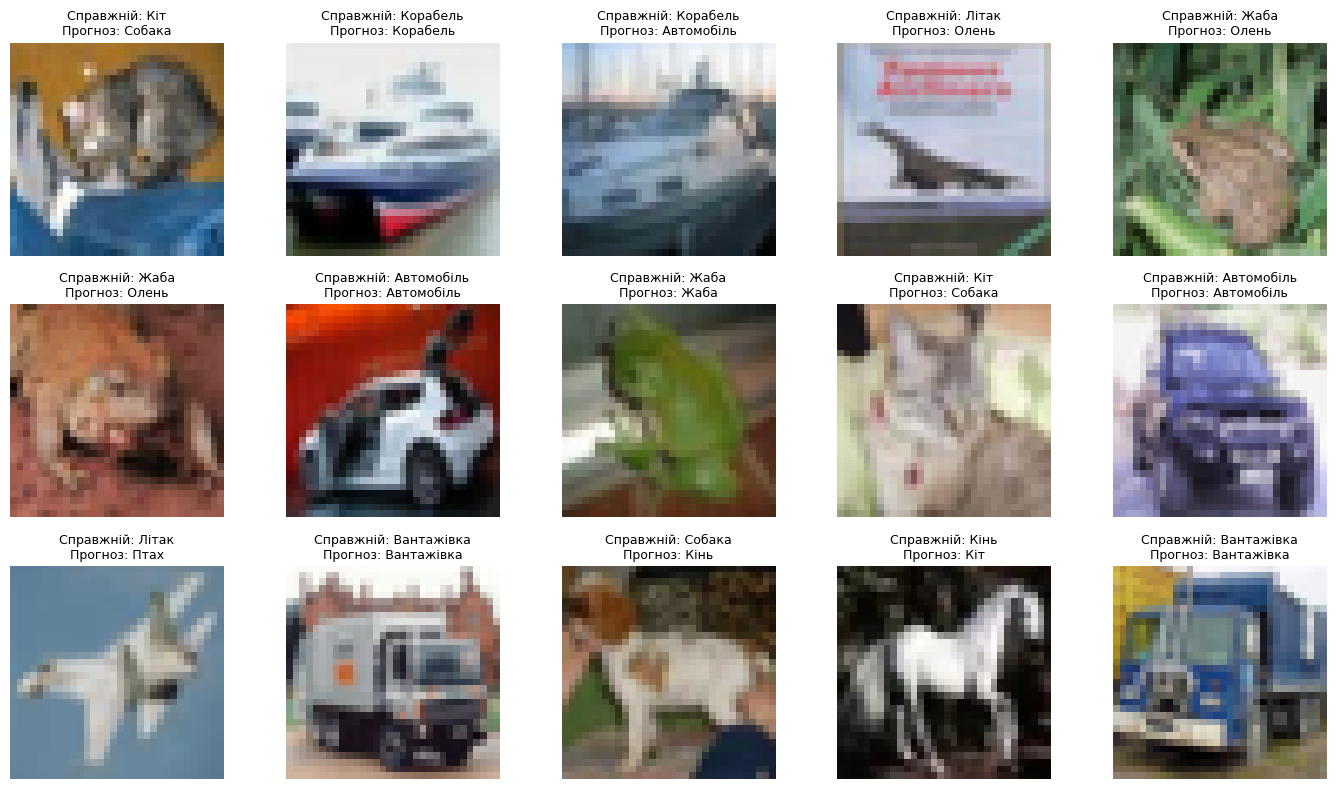

In [19]:
plt.figure(figsize=(14, 8))

predictions_vgg = vgg_model.predict(x_test_vgg[:15])
predicted_classes_vgg = np.argmax(predictions_vgg, axis=1)

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i])

    true_label = class_names[y_test_vgg[i]]
    predicted_label = class_names[predicted_classes_vgg[i]]

    plt.title(
        f'Справжній: {true_label}\nПрогноз: {predicted_label}',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


Висновок: у ході лабораторної роботи було створено та навчено згорткову нейронну мережу CNN для класифікації зображень CIFAR-10. Також було використано попередньо навчену модель VGG16 та виконано її тонке налаштування. Побудовано графіки точності й функції втрат, сформовано класифікаційні звіти та візуалізовано результати розпізнавання. Отримано практичні навички роботи зі згортковими нейронними мережами та Transfer Learning.